In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

In [2]:
train_data = (pd.read_csv('data/mnist_train.csv', header=None)
         .rename(columns={0: 'label'}))
test_data = (pd.read_csv('data/mnist_test.csv', header=None)
        .rename(columns={0: 'label'}))

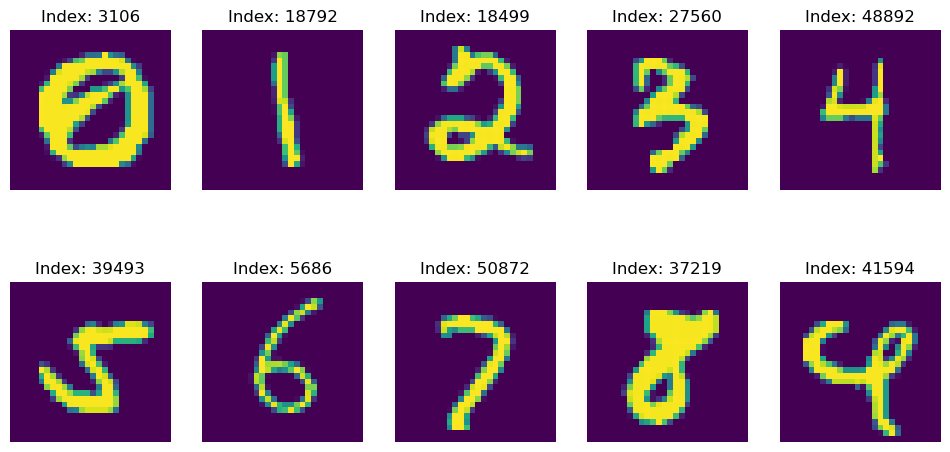

In [3]:
# Question 1a
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    sample = train_data.query(f'label == {i}').sample(n=1)
    plt.imshow(sample.values[0, 1:].reshape(28, 28))
    plt.title(f'Index: {sample.index[0]}')
    plt.axis('off')
plt.show()

In [20]:
# Question 1b
zeros = ((train_data.query('label == 0').iloc[:500] / 255)
         .assign(label=[-1] * 500))
ones = ((train_data.query('label == 1').iloc[:500] / 255)
        .assign(label=[1] * 500))
new_train = pd.concat([zeros, ones]).reset_index(drop=True)
new_train.head()

,label,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


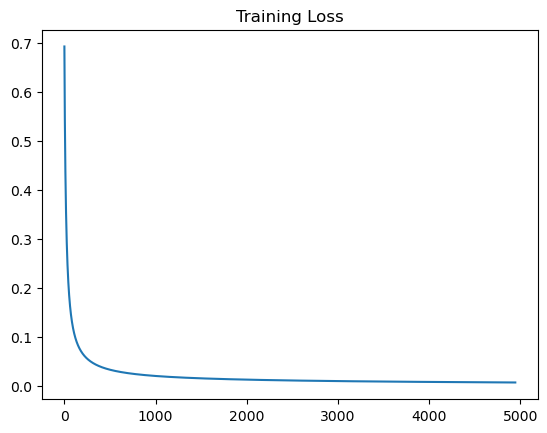

In [ ]:
# Question 1c
X = new_train.iloc[:, 1:].to_numpy()
Y = new_train.iloc[:, 0].to_numpy()
w = np.zeros(X.shape[1])

def loss(w, X, Y):
    log_reg = lambda w, x, y: np.log(1 + np.exp(-y * np.dot(x, w)))
    return np.mean([log_reg(w, x, y) for x, y in zip(X, Y)])

def grad(w, X, Y):
    sigmoid = lambda z: 1 / (1 + np.exp(-z))
    log_reg_grad = lambda w, x, y: sigmoid(-y * np.dot(x, w)) * (-y * x)
    return np.mean([log_reg_grad(w, x, y) for x, y in zip(X, Y)], axis=0)

def train(w, X, Y, mu = 1e-4, T = 10_000, stop_condition = 1e-2):
    losses = np.array([])

    for t in np.arange(T):
        curr_loss = loss(w, X, Y)
        gradient = grad(w, X, Y)
        grad_norm = np.linalg.norm(gradient)
        losses = np.append(losses, curr_loss)
        w = w - mu * gradient
        
        if t % 100 == 0:
            print(f'Step: {t}, Loss: {curr_loss}, Grad: {grad_norm}', end='\r')
            
        if np.linalg.norm(gradient) < stop_condition: 
            print(f'Step: {t}, Loss: {curr_loss}, Grad: {grad_norm}', end='\r')
            break
    
    plt.plot(losses)
    plt.title('Training Loss')
    plt.show()
    return w

w = train(w, X, Y, mu=1e-2, T=100_000)

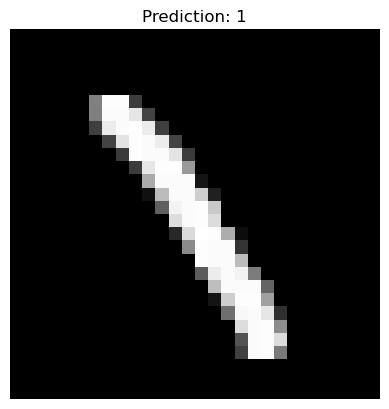

np.float64(1.0)

In [22]:
def predict(w, x, show=False):
    pred = np.sign(np.dot(x, w))
    if show:
        plt.imshow(x.reshape(28, 28), cmap='gray')
        plt.title(f'Prediction: {int((pred + 1) / 2)}')
        plt.axis('off')
        plt.show()
    return pred

predict(w, new_train.sample(1).iloc[0, 1:].to_numpy(), show=True)

In [23]:
# Question 1d
new_train.apply(lambda x: np.linalg.norm(x[1:].to_numpy()), axis=1).max()**-2 * 4

np.float64(0.018009574363339734)

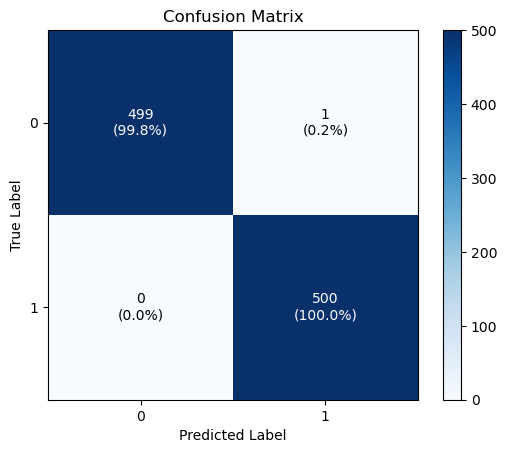

In [24]:
# Question 1e
zeros = ((test_data.query('label == 0').iloc[:500] / 255)
         .assign(label=[-1] * 500))
ones = ((test_data.query('label == 1').iloc[:500] / 255)
        .assign(label=[1] * 500))
new_test = pd.concat([zeros, ones]).reset_index(drop=True)

features = new_train.iloc[:, 1:].to_numpy()
labels = new_train.iloc[:, 0].to_numpy()
predictions = [predict(w, x) for x in features]

cm = confusion_matrix(labels, predictions)
cm_percentages = cm / cm.sum(axis=1, keepdims=True) * 100

plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')

for i, j in np.ndindex(cm.shape):
    plt.text(j, i, f'{cm[i, j]}\n({cm_percentages[i, j]:.1f}%)', 
        ha='center', va='center', 
        color='white' if cm_percentages[i, j] > 50 else 'black')

plt.colorbar()
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.show()

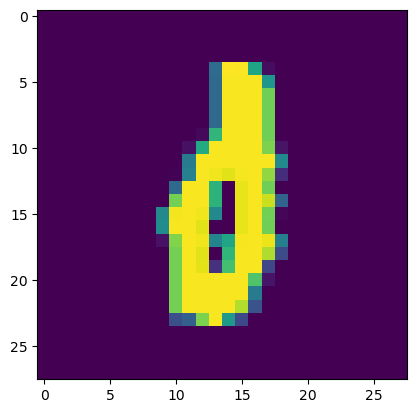

In [25]:
plt.imshow(new_train.loc[predictions[:500].index(1)].iloc[1:].to_numpy().reshape(28, 28))
plt.show()